# El salto en el filtro ambiente

En las mediciones, la curva del filtro cae, hace un **pozo** y después queda en una
**meseta** (entre −35 y −50 dB). El modelo ideal sigue cayendo.

**Hipótesis:** los C del filtro van a la masa de la caja, y esa masa vuelve a los aparatos
por mallas, conectores y patchera, con una impedancia chica $Z_g = R_g + j\omega L_g$.
Entonces la señal llega por dos caminos:
- **por el filtro:** cae con la frecuencia y, a alta frecuencia, queda invertida;
- **por la masa:** chica y casi constante.

Donde las dos son iguales se cancelan (el pozo). Más arriba queda la de la masa (la meseta).

```
Vg ─ 50 Ω ─ R ─┬─ R ─┬─ analizador 50 Ω ─ masa aparatos
               C     C                         │
               └──┬──┘                         │
             masa caja ──── Z_g = R_g + jωL_g ─┘
```

## 1. Modelo
**Qué hace esta celda:** carga las librerías y define tres cosas:
- `H(...)`: resuelve el circuito de arriba con Kirchhoff (análisis nodal) a cada frecuencia.
  Devuelve la señal **relativa al loopback** (generador → analizador directo da V/2), igual
  que las mediciones normalizadas con cable19. Con $Z_g = 0$ es el modelo ideal.
- `cargar_barrido(...)`: la misma función de `analisis_filtro_ambiente.ipynb`, que saca el
  pico de cada archivo del barrido.
- el estilo de los gráficos.

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.optimize import least_squares, minimize_scalar

R_GEN = 50   # Ω, generador
R_SA = 50    # Ω, analizador

def H(f, R, C, Rg=0.0, Lg=0.0):
    '''Señal a la salida relativa al loopback (2·V_salida/V_gen), para cada frecuencia de f.

    Nodos: 0 = entrada del filtro, 1 = medio, 2 = salida, 3 = masa de la caja.
    La masa de los aparatos es la referencia (V = 0).
    '''
    f = np.atleast_1d(f)
    resultado = np.empty(len(f), dtype=complex)
    for k, fr in enumerate(f):
        w = 2 * np.pi * fr
        y_C = 1j * w * C                    # admitancia de cada capacitor
        Z_g = Rg + 1j * w * Lg              # impedancia de la masa
        y_g = 1e12 if Z_g == 0 else 1 / Z_g # Z_g = 0: caja unida directo a la masa

        Y = np.zeros((4, 4), dtype=complex)
        def conectar(a, b, y):
            '''Suma una admitancia y entre los nodos a y b (b = None es la masa de los aparatos).'''
            Y[a, a] += y
            if b is not None:
                Y[b, b] += y
                Y[a, b] -= y
                Y[b, a] -= y

        conectar(0, None, 1 / R_GEN)   # resistencia interna del generador
        conectar(0, 1, 1 / R)          # primera R
        conectar(1, 2, 1 / R)          # segunda R
        conectar(2, None, 1 / R_SA)    # analizador
        conectar(1, 3, y_C)            # C del medio, a la masa de la caja
        conectar(2, 3, y_C)            # C de la salida, a la masa de la caja
        conectar(3, None, y_g)         # masa de la caja -> masa de los aparatos

        I = np.array([1 / R_GEN, 0, 0, 0])   # generador de 1 V como fuente de corriente (Norton)
        V = np.linalg.solve(Y, I)
        resultado[k] = 2 * V[2]
    return resultado

def dB(h):
    return 20 * np.log10(np.abs(h))

def cargar_barrido(carpeta):
    '''Lee los sweep_f_test_*.csv de una carpeta y devuelve frecuencia y amplitud del pico.'''
    filas = []
    for archivo in sorted(carpeta.glob("sweep_f_test_*.csv")):
        f_test = float(re.search(r"sweep_f_test_([\d.]+)kHz", archivo.name).group(1)) * 1e3
        amp = pd.read_csv(archivo)["Amplitude"].to_numpy()
        picos, _ = find_peaks(amp)   # máximo local, para no agarrar el borde de la ventana
        i = picos[np.argmax(amp[picos])] if len(picos) > 0 else int(np.argmax(amp))
        filas.append({"f_test": f_test, "peak_amp": amp[i]})
    return pd.DataFrame(filas).sort_values("f_test").reset_index(drop=True)

# Estilo de los gráficos
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a",
                                                          "#eda100", "#e87ba4", "#008300"])})
def cuadricula(ax):
    ax.grid(which="major", color="#cccccc", linewidth=0.8)
    ax.grid(which="minor", color="#ececec", linewidth=0.5)

**Validación.** Tiene que dar: 150 Ω / 1 µF ideal a 100 kHz → −75,5 dB. Con $R_g$ = 0,45 Ω y
$L_g$ = 0: pozo en 19,4 kHz (−66,5 dB) y −47,4 dB a 100 kHz. El pozo se busca con
`minimize_scalar` (el mínimo de la curva entre 3 y 100 kHz).

In [2]:
print(f"Ideal a 100 kHz:              {dB(H(1e5, 150, 1e-6))[0]:.1f} dB   (esperado −75,5)")
pozo = minimize_scalar(lambda lf: dB(H(10**lf, 150, 1e-6, 0.45, 0))[0], bounds=(3.5, 5), method="bounded")
print(f"Con R_g = 0,45 Ω: pozo en     {10**pozo.x/1e3:.1f} kHz ({pozo.fun:.1f} dB)   (esperado 19,4 kHz, −66,5 dB)")
print(f"Con R_g = 0,45 Ω a 100 kHz:   {dB(H(1e5, 150, 1e-6, 0.45, 0))[0]:.1f} dB   (esperado −47,4)")

Ideal a 100 kHz:              -75.5 dB   (esperado −75,5)
Con R_g = 0,45 Ω: pozo en     19.4 kHz (-66.5 dB)   (esperado 19,4 kHz, −66,5 dB)
Con R_g = 0,45 Ω a 100 kHz:   -47.4 dB   (esperado −47,4)


## 2. Simulación
**Qué hace:** a la izquierda, el canal 150 Ω / 1 µF con distintas $R_g$ ($L_g$ = 100 nH, salvo la
ideal). A la derecha, los 6 canales con $R_g$ = 0,45 Ω y $L_g$ = 100 nH.

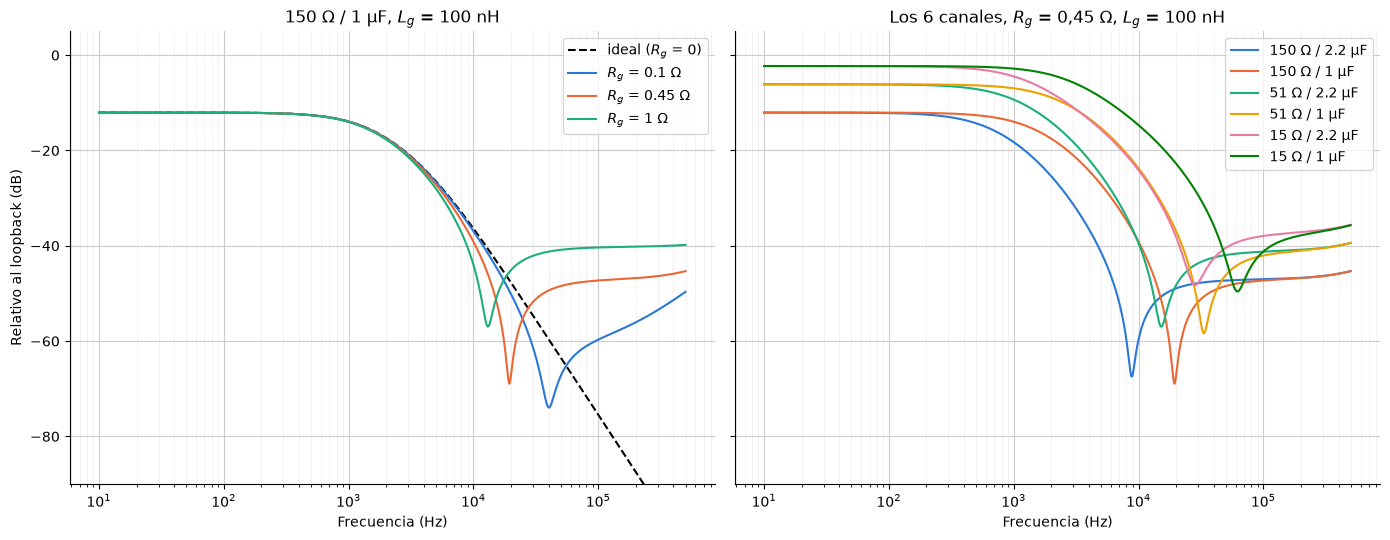

In [3]:
f = np.logspace(1, np.log10(5e5), 600)   # 10 Hz a 500 kHz

fig, (izq, der) = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

izq.semilogx(f, dB(H(f, 150, 1e-6)), "k--", label="ideal ($R_g$ = 0)")
for Rg in [0.1, 0.45, 1.0]:
    izq.semilogx(f, dB(H(f, 150, 1e-6, Rg, 100e-9)), label=f"$R_g$ = {Rg:g} Ω")
izq.set_title("150 Ω / 1 µF, $L_g$ = 100 nH")

canales_6 = [(150, 2.2e-6), (150, 1e-6), (51, 2.2e-6), (51, 1e-6), (15, 2.2e-6), (15, 1e-6)]
for R, C in canales_6:
    der.semilogx(f, dB(H(f, R, C, 0.45, 100e-9)), label=f"{R} Ω / {C*1e6:g} µF")
der.set_title("Los 6 canales, $R_g$ = 0,45 Ω, $L_g$ = 100 nH")

izq.set_ylabel("Relativo al loopback (dB)")
for ax in (izq, der):
    ax.set_xlabel("Frecuencia (Hz)")
    ax.set_ylim(-90, 5)
    cuadricula(ax)
    ax.legend()
plt.tight_layout()
plt.show()

## 3. Comparación con las mediciones
**Qué hace:** para cada canal carga el barrido, lo normaliza con el loopback de cable19 (resta
en dB) y ajusta tres parámetros con `least_squares` sobre la curva en dB:
- el **C real** (factor entre 0,7 y 1,3 del nominal),
- **$R_g$** y **$L_g$** de la masa.

Como el ajuste puede quedar en un mínimo local, prueba varios puntos de partida y se queda con
el mejor. Si una carpeta no existe, la saltea.

In [4]:
# Canal: (carpeta, R nominal, C nominal, frecuencia máxima para el ajuste o None)
canales = {
    "cable9":  ("../barridos/6/barrido_filtroamb_cable9",  150, 1e-6,   None),
    "cable2":  ("../barridos/5/barrido_filtroamb_cable2",  15,  2.2e-6, 40e3),   # sólo hasta 40 kHz
    "cable24": ("../barridos/5/barrido_filtroamb_cable24", 51,  2.2e-6, None),
    "cable23": ("../barridos/6/barrido_filtroamb_cable23", 51,  2.2e-6, None),
    "cable3":  ("../barridos/6/barrido_filtroamb_cable3",  15,  1e-6,   None),
    "cable13": ("../barridos/6/barrido_filtroamb_cable13", 51,  1e-6,   None),
    "cable18": ("../barridos/6/barrido_filtroamb_cable18", 150, 2.2e-6, None),
    "cable14": ("../barridos/6/barrido_filtroamb_cable14", 51,  1e-6,   None),
}
calibracion = cargar_barrido(Path("../barridos/5/barrido_automatico_cable19"))
puntos_de_partida = [(1, 0.1, 10), (1, 0.5, 100), (1, 1, 300), (0.9, 2, 50), (1.1, 0.3, 500)]  # (factor C, R_g en Ω, L_g en nH)

ajustes, datos = [], {}
for nombre, (carpeta, R, C, f_max) in canales.items():
    medido = cargar_barrido(Path(carpeta))
    if len(medido) == 0:
        print(f"{nombre}: no encontré datos en {carpeta}, lo salteo")
        continue

    # normalizar con el loopback (cable19), interpolando en log f
    ff = medido["f_test"].to_numpy()
    norm = medido["peak_amp"].to_numpy() - np.interp(np.log10(ff), np.log10(calibracion["f_test"]), calibracion["peak_amp"])
    usar = ff <= f_max if f_max else np.ones(len(ff), dtype=bool)

    # residuo: modelo − medición, en dB. p = (factor de C, R_g en Ω, L_g en nH)
    residuo = lambda p: dB(H(ff[usar], R, p[0] * C, p[1], p[2] * 1e-9)) - norm[usar]
    mejor = min((least_squares(residuo, p0, bounds=([0.7, 0, 0], [1.3, 20, 5000])) for p0 in puntos_de_partida),
                key=lambda s: s.cost)

    k, Rg, Lg = mejor.x
    ajustes.append({"canal": nombre, "R nominal (Ω)": R, "C nominal (µF)": C * 1e6,
                    "C ajustado (µF)": round(k * C * 1e6, 3), "R_g (mΩ)": round(Rg * 1e3),
                    "L_g (nH)": round(Lg), "error rms (dB)": round(np.sqrt(np.mean(mejor.fun**2)), 2)})
    datos[nombre] = (ff, norm, R, C, k, Rg, Lg, f_max)

if not datos:
    print(f"No encontré ninguna carpeta de barridos. Estoy en: {Path.cwd()}")
pd.DataFrame(ajustes).set_index("canal")

,R nominal (Ω),C nominal (µF),C ajustado (µF),R_g (mΩ),L_g (nH),error rms (dB)
canal,,,,,,
cable9,150,1.0,0.886,454,94,0.15
cable2,15,2.2,2.035,465,50,0.19
cable24,51,2.2,2.045,1152,121,0.11
cable23,51,2.2,1.983,471,107,0.16
cable3,15,1.0,0.863,2168,137,0.22
cable13,51,1.0,0.880,1931,124,0.13
cable18,150,2.2,2.003,1644,135,0.13
cable14,51,1.0,0.876,673,111,0.15


**Qué hace:** un gráfico por canal con la medición (puntos), el modelo ideal (punteado) y el
modelo con masa ajustado (línea). En cable2 la zona sombreada quedó fuera del ajuste.

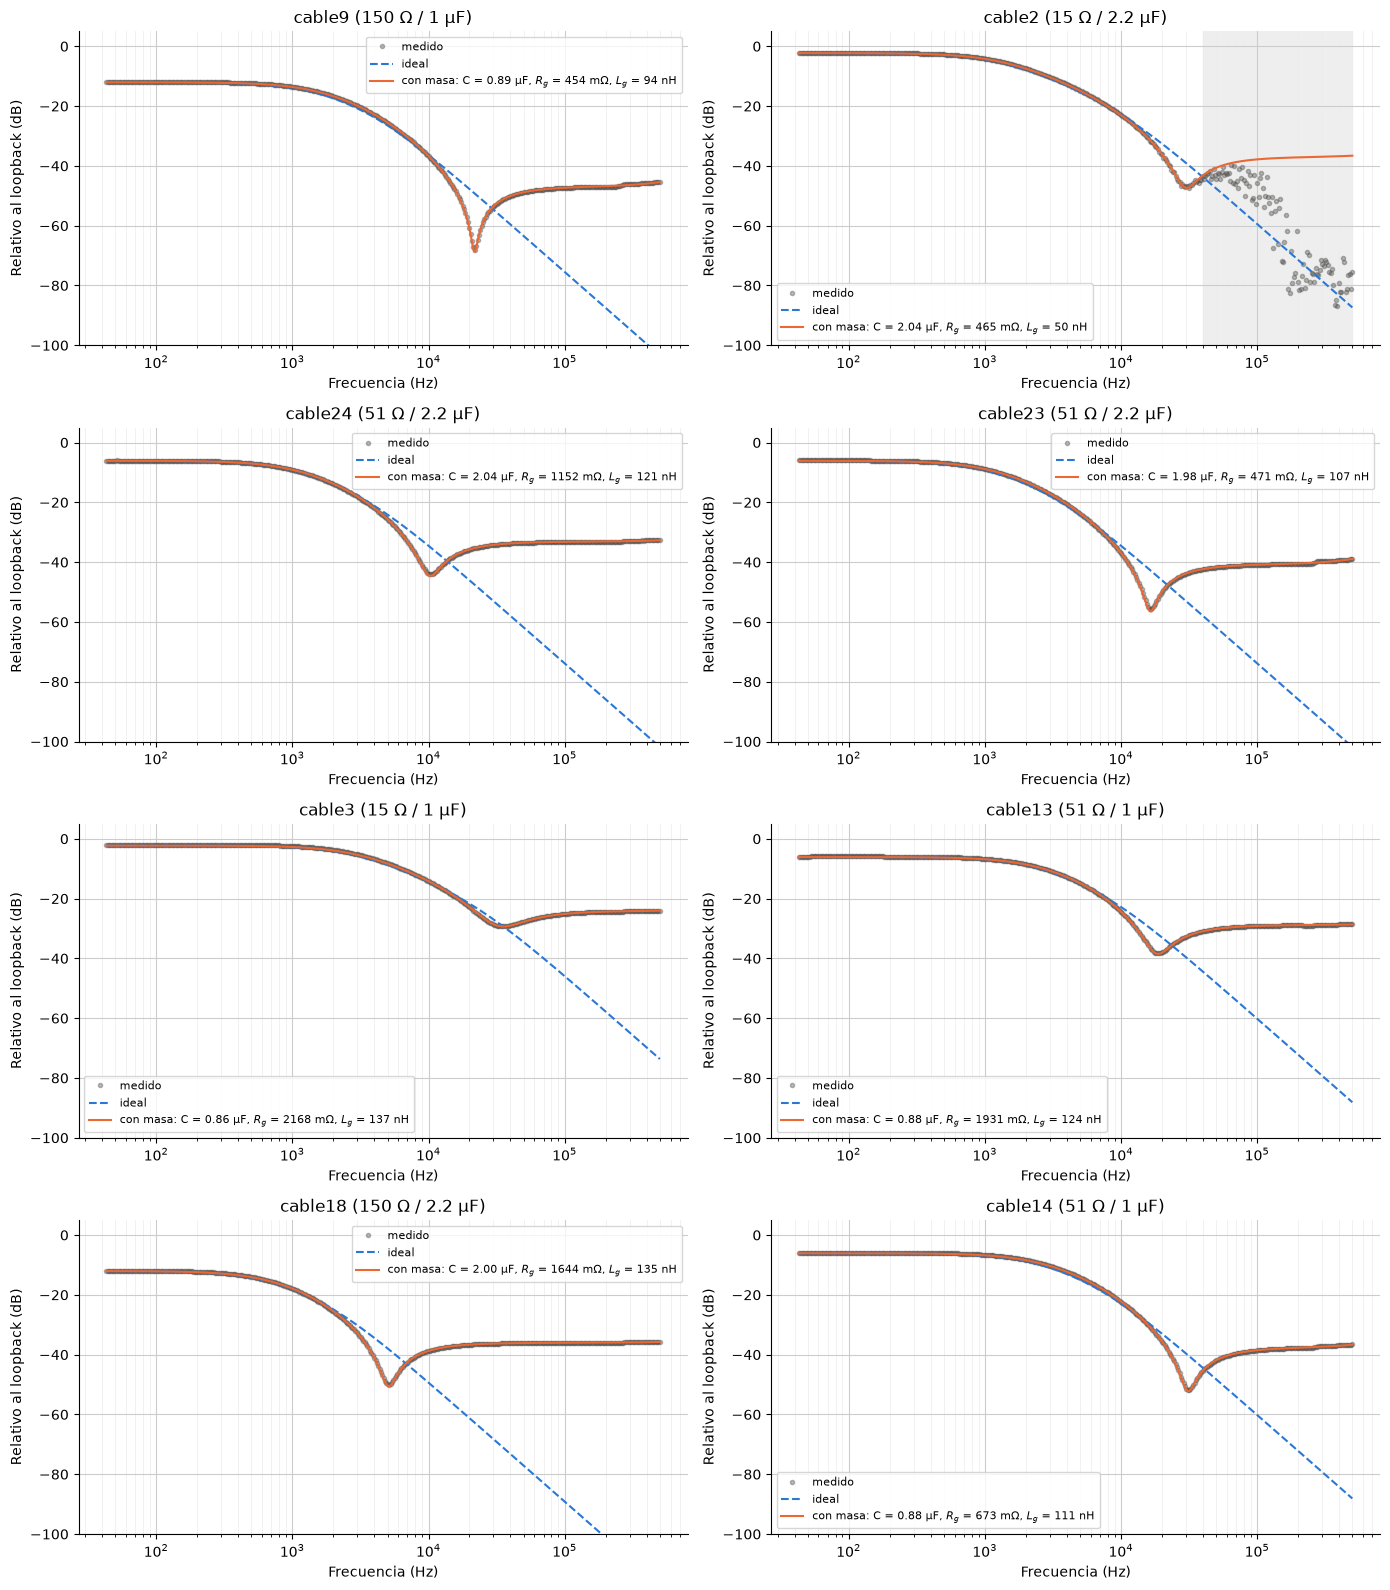

In [5]:
n = len(datos)
fig, axs = plt.subplots((n + 1) // 2, 2, figsize=(14, 4 * ((n + 1) // 2)), squeeze=False)
for ax, (nombre, (ff, norm, R, C, k, Rg, Lg, f_max)) in zip(axs.flat, datos.items()):
    fm = np.logspace(np.log10(ff.min()), np.log10(ff.max()), 400)
    ax.semilogx(ff, norm, "o", markersize=3, alpha=0.4, color="#52514e", label="medido")
    ax.semilogx(fm, dB(H(fm, R, C)), "--", color="#2a78d6", label="ideal")
    ax.semilogx(fm, dB(H(fm, R, k * C, Rg, Lg * 1e-9)), color="#eb6834",
                label=f"con masa: C = {k*C*1e6:.2f} µF, $R_g$ = {Rg*1e3:.0f} mΩ, $L_g$ = {Lg:.0f} nH")
    if f_max:
        ax.axvspan(f_max, ff.max(), color="#eeeeee", zorder=0)
    ax.set_title(f"{nombre} ({R} Ω / {C*1e6:g} µF)")
    ax.set_ylim(-100, 5)
    ax.set_xlabel("Frecuencia (Hz)")
    ax.set_ylabel("Relativo al loopback (dB)")
    cuadricula(ax)
    ax.legend(fontsize=8)
for ax in list(axs.flat)[n:]:
    ax.remove()
plt.tight_layout()
plt.show()